# Color, Layout, and Accessibility

Colour is the most powerful and the most misused visual channel. About 1 in 12 men and 1 in 200 women have a colour-vision deficiency; many readers see charts on small screens, in dark mode or printed in grey. An accessible chart works for all of them.

**After this lesson you can:**

1. Choose categorical, sequential and diverging palettes for the data type.
2. Simulate colour-vision deficiency and check a palette.
3. Compute WCAG contrast ratios for text and marks.
4. Use direct labels, annotations and grid layouts to guide the reader.

**Data:** Gapminder, Seattle weather and NYC taxi trips.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

import matplotlib.colors as mcolors

gap = pd.read_json(datasets.fetch("gapminder.json"))
weather = pd.read_csv(datasets.fetch("seattle-weather.csv"), parse_dates=["date"])

## 1. Three Kinds of Palettes

| Data | Palette | Example |
| :--- | :--- | :--- |
| categories without order | **categorical**: distinct hues, similar lightness | regions, species |
| ordered values from low to high | **sequential**: one hue, light → dark | rainfall, counts |
| values around a meaningful midpoint | **diverging**: two hues, neutral centre | change vs last year, anomalies |

`viridis`, `cividis`, `magma` are **perceptually uniform** sequential palettes: equal steps in data look like equal steps in colour, and they stay ordered in greyscale. The old `jet`/rainbow palette is not uniform and creates false boundaries.

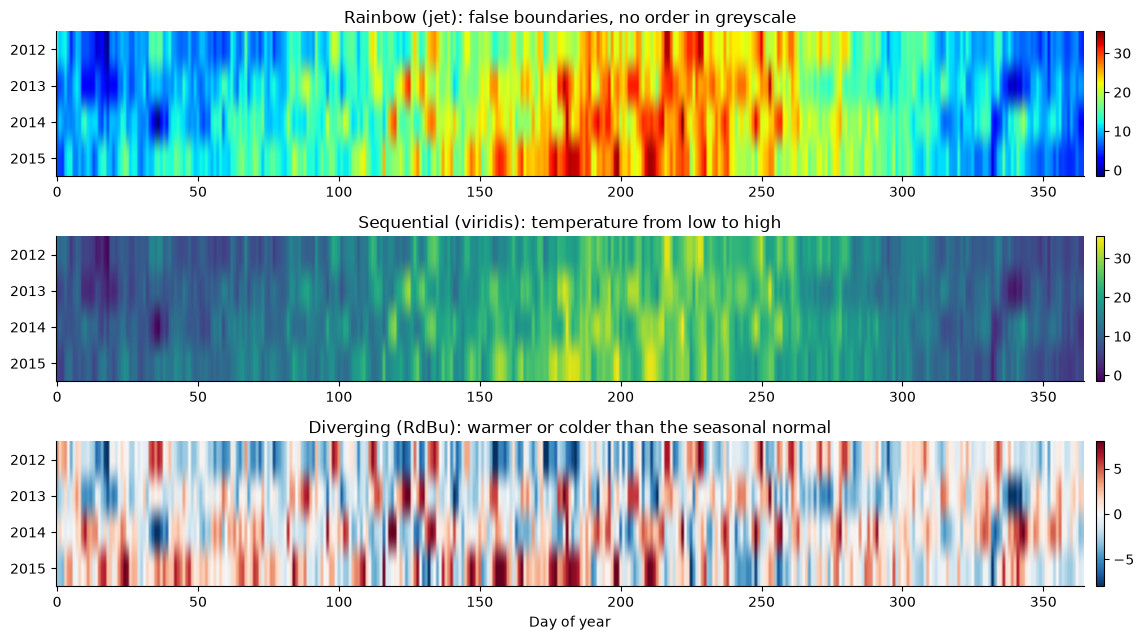

In [2]:
w = weather.assign(year=weather["date"].dt.year, doy=weather["date"].dt.day_of_year)
grid = w[w["doy"] <= 365].pivot(index="year", columns="doy", values="temp_max")
anom = grid - grid.mean(axis=0).rolling(15, center=True, min_periods=1).mean()

fig, axes = plt.subplots(3, 1, figsize=(13, 6.5))
for ax, data, cmap, title, kw in [
    (axes[0], grid, "jet", "Rainbow (jet): false boundaries, no order in greyscale", {}),
    (axes[1], grid, "viridis", "Sequential (viridis): temperature from low to high", {}),
    (axes[2], anom, "RdBu_r", "Diverging (RdBu): warmer or colder than the seasonal normal", {"vmin": -8, "vmax": 8}),
]:
    im = ax.imshow(data, aspect="auto", cmap=cmap, **kw)
    ax.set(yticks=range(len(data)), yticklabels=data.index, title=title)
    fig.colorbar(im, ax=ax, pad=0.01)
axes[2].set_xlabel("Day of year")
plt.tight_layout()
plt.show()

## 2. Simulate Colour-Vision Deficiency

**Deuteranopia** and **protanopia** (red–green deficiencies) are the most common forms. The function below applies the simulation matrices of Machado et al. (2009, severity 1.0) in linear RGB to approximate what a person with the deficiency sees.

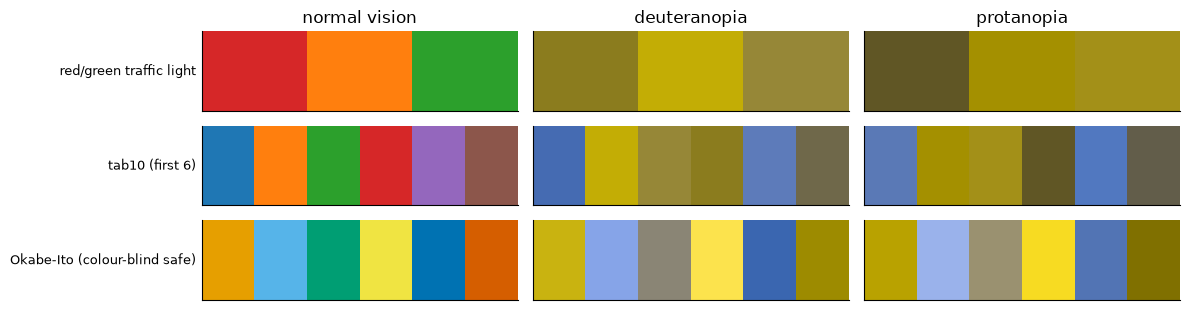

red/green traffic light          smallest colour distance under deuteranopia: 0.116
tab10 (first 6)                  smallest colour distance under deuteranopia: 0.115
Okabe-Ito (colour-blind safe)    smallest colour distance under deuteranopia: 0.242


In [3]:
MACHADO = {
    "deuteranopia": np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
    "protanopia": np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
}

def to_linear(c):
    c = np.asarray(c, dtype=float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def to_srgb(c):
    c = np.clip(c, 0, 1)
    return np.where(c <= 0.0031308, 12.92 * c, 1.055 * c ** (1 / 2.4) - 0.055)

def simulate(colors, kind):
    rgb = np.array([mcolors.to_rgb(c) for c in colors])
    return to_srgb(to_linear(rgb) @ MACHADO[kind].T)

palettes = {
    "red/green traffic light": ["#D62728", "#FF7F0E", "#2CA02C"],
    "tab10 (first 6)": list(plt.cm.tab10.colors[:6]),
    "Okabe-Ito (colour-blind safe)": ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00"],
}
fig, axes = plt.subplots(len(palettes), 3, figsize=(12, 3.2))
for r, (name, pal) in enumerate(palettes.items()):
    for c, (label, cols) in enumerate([("normal vision", np.array([mcolors.to_rgb(x) for x in pal])),
                                       ("deuteranopia", simulate(pal, "deuteranopia")),
                                       ("protanopia", simulate(pal, "protanopia"))]):
        axes[r, c].imshow(cols[np.newaxis, :, :], aspect="auto")
        axes[r, c].set(xticks=[], yticks=[])
        if r == 0:
            axes[r, c].set_title(label)
        if c == 0:
            axes[r, c].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.show()

def min_distance(cols):
    lab = np.asarray(cols)
    return min(np.linalg.norm(lab[i] - lab[j]) for i in range(len(lab)) for j in range(i + 1, len(lab)))
for name, pal in palettes.items():
    print(f"{name:<32} smallest colour distance under deuteranopia: {min_distance(simulate(pal, 'deuteranopia')):.3f}")

Red and green become almost the same brown under deuteranopia. The **Okabe–Ito** palette stays distinguishable. Never use colour as the **only** carrier of meaning: add labels, shapes or position.

## 3. Contrast Ratio (WCAG)

The Web Content Accessibility Guidelines define the contrast ratio between two colours from their relative luminance $L$:

$$\text{ratio} = \frac{L_{\text{lighter}} + 0.05}{L_{\text{darker}} + 0.05}$$

WCAG 2.x asks for at least **4.5 : 1** for normal text and **3 : 1** for large text and for graphical objects that carry meaning.

In [4]:
def luminance(color):
    r, g, b = to_linear(mcolors.to_rgb(color))
    return 0.2126 * r + 0.7152 * g + 0.0722 * b

def contrast(c1, c2):
    l1, l2 = sorted([luminance(c1), luminance(c2)], reverse=True)
    return (l1 + 0.05) / (l2 + 0.05)

pairs = [("#FFFFFF", "#000000"), ("#FFFFFF", "#4E79A7"), ("#FFFFFF", "#BAB0AC"), ("#FFFFFF", "#F0E442"),
         ("#FFFFFF", "#767676"), ("#1E1E1E", "#4E79A7")]
rows = [{"background": bg, "foreground": fg, "ratio": round(contrast(bg, fg), 2),
         "text 4.5:1": contrast(bg, fg) >= 4.5, "graphics 3:1": contrast(bg, fg) >= 3} for bg, fg in pairs]
pd.DataFrame(rows)

,background,foreground,ratio,text 4.5:1,graphics 3:1
0,#FFFFFF,#000000,21.00,True,True
1,#FFFFFF,#4E79A7,4.55,True,True
2,#FFFFFF,#BAB0AC,2.12,False,False
3,#FFFFFF,#F0E442,1.32,False,False
4,#FFFFFF,#767676,4.54,True,True
5,#1E1E1E,#4E79A7,3.67,False,True


Light grey (`#BAB0AC`) and yellow on white fail even the 3 : 1 rule for graphics. `#767676` is the lightest grey that passes 4.5 : 1 on white. Check the colours of your chart against the background it will be shown on, also in dark mode.

## 4. Layout and Direct Labels

- Arrange panels so that the eye moves in reading order and shared axes line up.
- Label lines and bars **directly** instead of a legend.
- Use **annotations** to explain the point that matters.
- Use grey for context and **one** accent colour for the focus.

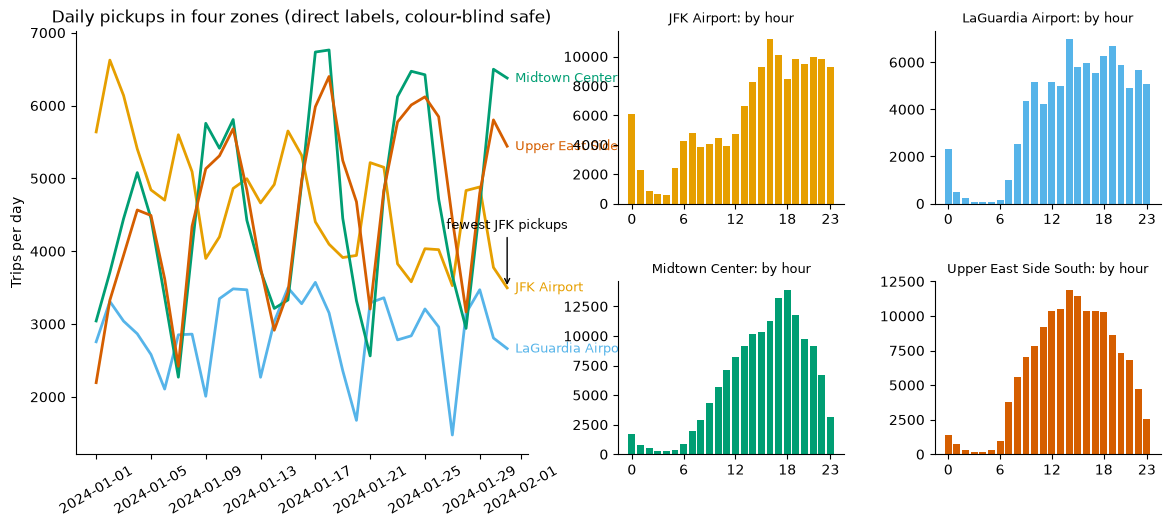

In [5]:
taxi = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "PULocationID"])
taxi = taxi[taxi["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left")]
daily = taxi.groupby([taxi["tpep_pickup_datetime"].dt.date, "PULocationID"]).size().unstack(fill_value=0)
focus = {132: "JFK Airport", 138: "LaGuardia Airport", 161: "Midtown Center", 237: "Upper East Side South"}
OKABE = ["#E69F00", "#56B4E9", "#009E73", "#D55E00"]

fig = plt.figure(figsize=(14, 5.5))
gs = fig.add_gridspec(2, 3, width_ratios=[2, 1, 1], hspace=0.45, wspace=0.3)
ax_main = fig.add_subplot(gs[:, 0])
for (zid, name), color in zip(focus.items(), OKABE):
    s = daily[zid]
    ax_main.plot(s.index, s.values, color=color, lw=2)
    ax_main.text(s.index[-1], s.values[-1], f"  {name}", color=color, va="center", fontsize=9)
low_day = daily[132].idxmin()
ax_main.annotate("fewest JFK pickups", xy=(low_day, daily.loc[low_day, 132]), xytext=(low_day, daily[132].max() * 0.65),
                 arrowprops=dict(arrowstyle="->", color="black"), ha="center", fontsize=9)
ax_main.set(title="Daily pickups in four zones (direct labels, colour-blind safe)", ylabel="Trips per day")
ax_main.tick_params(axis="x", rotation=30)
for i, ((zid, name), color) in enumerate(zip(focus.items(), OKABE)):
    ax = fig.add_subplot(gs[i // 2, 1 + i % 2])
    hours = taxi.loc[taxi["PULocationID"] == zid, "tpep_pickup_datetime"].dt.hour.value_counts().sort_index()
    ax.bar(hours.index, hours.values, color=color)
    ax.set_title(f"{name}: by hour", fontsize=9)
    ax.set_xticks([0, 6, 12, 18, 23])
plt.show()

## 5. Accessibility Checklist

| Check | Rule of thumb |
| :--- | :--- |
| colour-vision deficiency | colour-blind-safe palette; never colour alone |
| contrast | ≥ 3 : 1 for marks, ≥ 4.5 : 1 for text |
| text size | ≥ 9–10 pt at the final display size |
| alternative text | describe the chart's message for screen readers (`alt` text) |
| dark mode | test on dark backgrounds; avoid transparent PNG backgrounds |
| greyscale | the chart still works when printed in grey |

*Insight: Use colour with intent: a categorical, sequential or diverging palette that matches the data, one accent colour for the message, and labels or shapes in addition to colour. Check contrast and colour-blind simulations before you publish.*

## Real-World Use Case or Analogy

Accessible charts are like **ramps at a building entrance**: they are essential for some people and make the entrance easier for everyone (a parent with a pram, a delivery person). A chart that works in greyscale and for colour-blind readers is also clearer on a projector and on a phone.

Public-sector websites must follow accessibility laws (for example the European Accessibility Act and Section 508 in the US), and many companies require WCAG compliance for internal dashboards.